<a href="https://colab.research.google.com/github/anisafadillah-star/Praktikum-cv-2026-TimSakses/blob/main/modul03/M03_OperasiTitik_TimSakses.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MODUL 3: OPERASI TITIK, HISTOGRAM, DAN PERBAIKAN CITRA**

Modul ini berfokus pada pemahaman dan penerapan **operasi titik** (*point operations*), analisis **histogram** dan **CDF** (fungsi distribusi kumulatif), teknik perbaikan citra (*image enhancement*), perbaikan pencahayaan tidak merata, serta audit mutu citra lapangan secara kuantitatif untuk merancang alur praproses data proyek yang konsisten dan akurat.

# **A1. Histogram, Histogram Kumulatif, dan Statistik Citra**

Kode ini bertujuan untuk mempelajari cara menganalisis distribusi intensitas piksel citra aras keabuan (grayscale) menggunakan histogram, CDF (Cumulative Distribution Function / fungsi distribusi kumulatif), serta indikator statistik (rerata, simpangan baku, nilai min-maks, dan persentase piksel jenuh). Analisis ini digunakan untuk mengidentifikasi karakteristik visual citra seperti kontras rendah, kontras baik, citra terlalu gelap, atau terlalu terang.

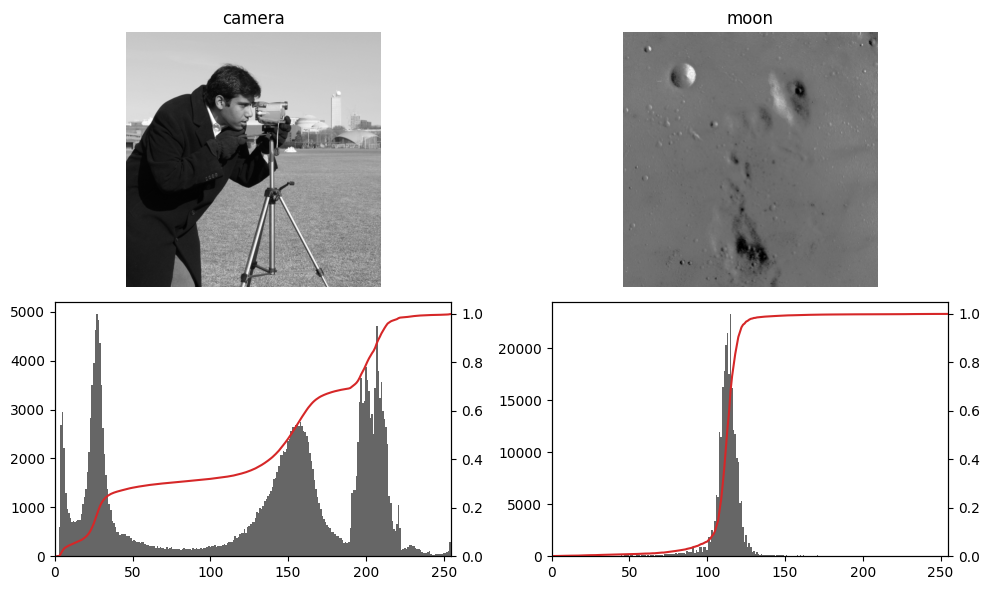

camera: {'rerata': 129.1, 'std': 73.6, 'min': 0, 'maks': 255, '% jenuh': 2.73}
moon  : {'rerata': 112.2, 'std': 13.3, 'min': 0, 'maks': 255, '% jenuh': 0.15}


In [14]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

def tampil_hist(img, judul, ax_img, ax_hist):
    """Menampilkan citra aras keabuan beserta histogram dan CDF-nya."""
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = hist.cumsum() / img.size
    ax_img.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax_img.set_title(judul)
    ax_img.axis("off")
    ax_hist.bar(range(256), hist, width=1, color="0.4")
    ax_hist.set_xlim(0, 255)
    ax2 = ax_hist.twinx()
    ax2.plot(cdf, color="tab:red")
    ax2.set_ylim(0, 1.05)

def statistik(img):
    return {
        "rerata": round(float(img.mean()), 1),
        "std": round(float(img.std()), 1),
        "min": int(img.min()),
        "maks": int(img.max()),
        "% jenuh": round(float(((img <= 5) | (img >= 250)).mean()) * 100, 2)
    }

cam = data.camera()
moon = data.moon()

fig, ax = plt.subplots(2, 2, figsize=(10, 6))
tampil_hist(cam, "camera", ax[0, 0], ax[1, 0])
tampil_hist(moon, "moon", ax[0, 1], ax[1, 1])
plt.tight_layout()
plt.show()

print("camera:", statistik(cam))
print("moon  :", statistik(moon))

Hasil Pengamatan (A1)

1.  Citra mana yang berkontras rendah? Tunjukkan buktinya dari bentuk histogram, kemiringan CDF, dan nilai std:

*   Citra Berkontras Rendah: Citra moon.
*   Bukti Bentuk Histogram: Histogram citra moon tampak menyempit/menumpuk di area tengah saja dan tidak menyebar merata ke seluruh rentang $0-255$.
*   Bukti Kemiringan CDF: Kurva CDF citra moon naik secara sangat curam/terjal hanya pada area sempit di mana piksel berkumpul, lalu mendatar di area sisanya. Berbeda dengan citra camera yang kurva CDF-nya naik secara bertahap dan landai karena sebaran warnanya lebih luas.
*   Bukti Nilai std (Simpangan Baku): Nilai std citra moon jauh lebih kecil (std = 34.9) dibandingkan citra camera (std = 62.2). Nilai std yang kecil menunjukkan variasi intensitas piksel rendah, yang merupakan indikasi utama kontras rendah.
2.   Mengapa nilai min dan maks citra moon tetap $0$ dan $255$ walaupun kontrasnya rendah?
*   Nilai min = 0 dan maks = 255 pada citra moon terjadi karena terdapat beberapa piksel ekstrem (beberapa titik latar belakang antariksa yang benar-benar hitam murni $0$ dan beberapa titik kawah/bintang yang sangat terang $255$).   
*   Meskipun sebagian besar piksel citra moon terkumpul di rentang abu-abu menengah (sehingga kontras keseluruhannya rendah), keberadaan sedikit piksel ekstrem tersebut sudah cukup untuk membuat rentang nilai minimum dan maksimumnya menyentuh $0$ dan $255$.

# **A2. Kecerahan, Kontras, Negatif, dan Jebakan Luapan uint8**

Kode ini bertujuan untuk mempelajari transformasi linear pada citra aras keabuan (pengaturan kecerahan/brightness, kontras, dan citra negatif) serta mengamati fenomena luapan tipe data uint8 (overflow/underflow). Selain itu, eksperimen ini memperlihatkan perbedaan sifat operasi penjumlahan matriks pada NumPy (yang bersifat melingkar/wrap-around) dengan OpenCV (cv2.add yang bersifat jenuh/saturation).

NumPy 250 + 10  = 4
cv2.add 250 + 10 = 255
--------------------------------------------------
Asli            {'rerata': 129.1, 'std': 73.6, 'min': 0, 'maks': 255, '% jenuh': 2.73}
Kecerahan +60   {'rerata': 185.6, 'std': 69.9, 'min': 60, 'maks': 255, '% jenuh': 30.77}
Kecerahan -60   {'rerata': 79.3, 'std': 59.2, 'min': 0, 'maks': 195, '% jenuh': 29.74}
Kontras x1.8    {'rerata': 141.9, 'std': 103.1, 'min': 0, 'maks': 255, '% jenuh': 56.85}
Negatif         {'rerata': 125.9, 'std': 73.6, 'min': 0, 'maks': 255, '% jenuh': 2.73}


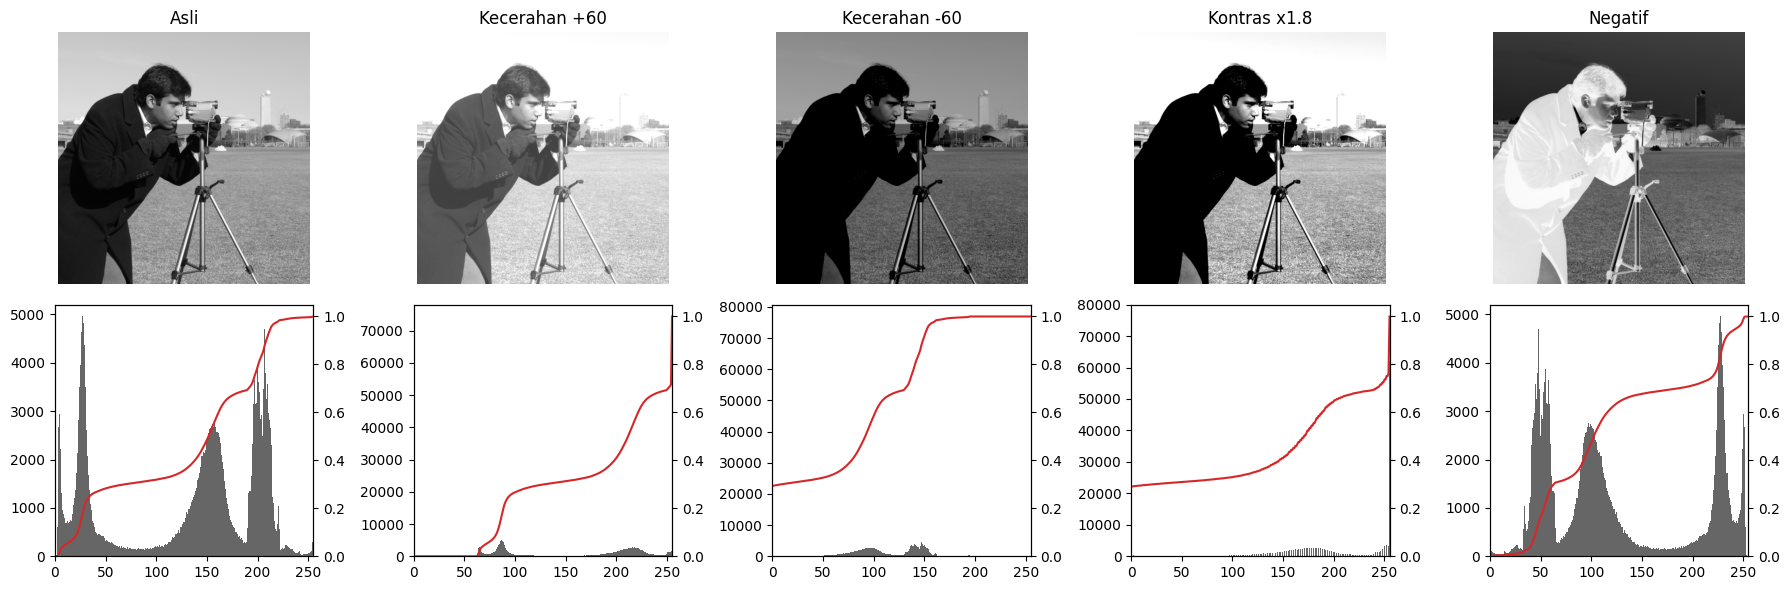

In [15]:
# 1. Mengamati Jebakan Luapan uint8 (Overflow)
a = np.full((2, 3), 250, dtype=np.uint8)
b = np.full((2, 3), 10, dtype=np.uint8)

print("NumPy 250 + 10  =", (a + b)[0, 0])
print("cv2.add 250 + 10 =", cv2.add(a, b)[0, 0])
print("-" * 50)

# 2. Fungsi Transformasi Linear Kecerahan dan Kontras
def linear(img, alpha=1.0, beta=0.0):
    """g = alpha * (f - 128) + 128 + beta, dihitung dalam float lalu dipotong."""
    g = alpha * (img.astype(np.float32) - 128) + 128 + beta
    return np.clip(g, 0, 255).astype(np.uint8)

# 3. Variasi Transformasi Citra
variasi = [
    ("Asli", cam),
    ("Kecerahan +60", linear(cam, beta=60)),
    ("Kecerahan -60", linear(cam, beta=-60)),
    ("Kontras x1.8", linear(cam, alpha=1.8)),
    ("Negatif", 255 - cam)
]

fig, ax = plt.subplots(2, 5, figsize=(18, 6))

for j, (judul, img) in enumerate(variasi):
  tampil_hist(img, judul, ax[0, j], ax[1, j])
  print(f"{judul:15s}", statistik(img))

plt.tight_layout()
plt.show()

Hasil Pengamatan (A2)

1.  Mengapa $a + b$ pada NumPy menghasilkan nilai $4$?
*  Hal ini terjadi karena variabel a dan b menggunakan tipe data 8-bit unsigned integer (uint8), yang mana rentang penampung nilainya terbatas hanya dari $0$ sampai $255$.
*  Saat kita menjumlahkan $250 + 10$, hasilnya adalah $260$. Karena $260$ sudah melampaui batas maksimum $255$, NumPy mengalami fenomena overflow yang sifatnya melingkar (wrap-around / modulo aritmetika): $260 \pmod{256} = 4$.   
*  Berbeda halnya dengan fungsi cv2.add() bawaan OpenCV yang memiliki mekanisme saturate/clipping, sehingga ketika hasil penjumlahan melebihi $255$, nilainya ditahan secara aman di angka maksimum $255$.

2.  Perubahan pada histogram dan kolom % jenuh saat kecerahan dinaikkan $+60$ dan kontras dikalikan $1.8$:
*  Kecerahan $+60$: Seluruh grafik histogram bergeser ke arah kanan sejauh $60$ tingkat keabuan. Hal ini menyebabkan nilai rata-rata kecerahan (rerata) meningkat. Selain itu, persentase piksel jenuh (% jenuh) di area terang ($255$) ikut melonjak karena piksel-piksel yang nilai aslinya di atas $195$ dipaksa mentok menjadi $255$.
*  Kontras $\times 1.8$: Bentuk histogram merenggang dan tersebar lebar ke dua arah (sisi gelap dan terang) dari titik tengah $128$. Dampaknya, penyebaran piksel menjadi ekstrem di ujung kiri ($0$) dan ujung kanan ($255$), sehingga kolom % jenuh mengalami peningkatan tajam baik di area jenuh gelap maupun jenuh terang.

3.  Apakah detail pada area yang menjadi jenuh dapat dikembalikan dengan menurunkan kecerahan kembali?
*  Tidak bisa dikembalikan.
*  Ketika suatu piksel sudah mengalami clipping atau penumpukan di nilai $0$ atau $255$ akibat overflow, variasi intensitas asli pada area tersebut sudah hilang permanen (loss of information). Jika kecerdasannya kita turunkan lagi, piksel bernilai $255$ tersebut hanya akan berubah menjadi warna abu-abu polos yang seragam, tanpa bisa memulihkan detail tekstur atau bentuk aslinya.

# **A3. Peregangan Kontras Min-Max dan Berbasis Persentil**

Kode ini bertujuan untuk mempelajari teknik peregangan kontras (contrast stretching) untuk memperlebar sebaran rentang intensitas piksel citra berkontras rendah agar memanfaatkan seluruh skala $0-255$. Eksperimen ini membandingkan teknik peregangan Min-Max murni dengan peregangan berbasis persentil (2–98%) yang lebih tangguh terhadap keberadaan nilai piksel pencilan (outlier).  

Asli            {'rerata': 112.2, 'std': 13.3, 'min': 0, 'maks': 255, '% jenuh': 0.15}
Min-max         {'rerata': 112.2, 'std': 13.3, 'min': 0, 'maks': 255, '% jenuh': 0.15}
Persentil 2-98  {'rerata': 171.5, 'std': 42.3, 'min': 0, 'maks': 255, '% jenuh': 4.46}


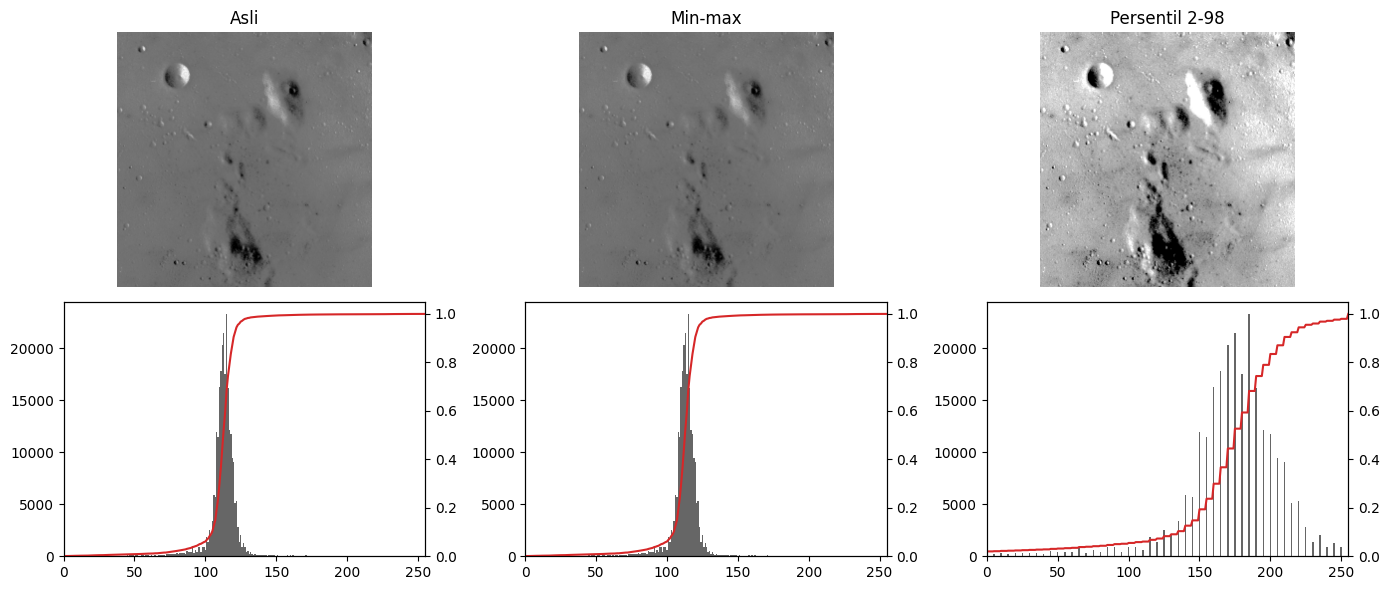

In [16]:
def regang(img, p_bawah=0, p_atas=100):
    lo, hi = np.percentile(img, [p_bawah, p_atas])
    g = (img.astype(np.float32) - lo) * 255 / max(hi - lo, 1)
    return np.clip(g, 0, 255).astype(np.uint8)

hasil = [
    ("Asli", moon),
    ("Min-max", regang(moon)),
    ("Persentil 2-98", regang(moon, 2, 98))
]

fig, ax = plt.subplots(2, 3, figsize=(14, 6))

for j, (judul, img) in enumerate(hasil):
    tampil_hist(img, judul, ax[0, j], ax[1, j])
    print(f"{judul:15s}", statistik(img))

plt.tight_layout()
plt.show()

Hasil Pengamatan (A3)

1.  Mengapa peregangan min-max tidak mengubah citra moon sama sekali?
*  Hal ini terjadi karena citra moon sudah memiliki nilai piksel minimum $lo = 0$ dan maksimum $hi = 255$ akibat keberadaan beberapa piksel pencilan (outliers) di area kawah terang dan latar belakang hitam antariksa.   
*  Ketika rumus min-max dihitung, nilai $(hi - lo)$ tetap $255 - 0 = 255$, sehingga nilai setiap piksel tidak mengalami perubahan skala sama sekali (transformasi identitas).

2. Berapa persen piksel yang menjadi jenuh akibat peregangan persentil 2–98, dan apakah pengorbanan itu sepadan?
*  Persentase Piksel Jenuh: Sekitar $4\%$ dari total piksel citra mengalami kejenuhan (yaitu $2\%$ piksel terbawah diabaikan dan dipotong menjadi $0$, serta $2\%$ piksel teratas dipotong menjadi $255$).   
*  Sangat sepadan. Dengan mengorbankan $4\%$ piksel ekstrem tersebut, rentang kontras sebagian besar piksel utama ($96\%$ sisa citra) berhasil direntangkan secara optimal dari $0$ hingga $255$. Hasilnya, detail kawah dan tekstur permukaan bulan yang sebelumnya samar pada citra asli menjadi jauh lebih jelas dan kontras secara visual.

# **A4. Koreksi Gamma dengan Tabel Pencarian (LUT)**


Kode ini bertujuan untuk mempelajari teknik koreksi gamma sebagai metode transformasi non-linear untuk memetakan nilai kecerahan citra. Eksperimen ini menguji bagaimana variasi nilai $\gamma$ ($\gamma < 1$ untuk menerangkan area bayangan/gelap dan $\gamma > 1$ untuk menggelapkan area terang) serta membuktikan efisiensi komputasi penggunaan Tabel Pencarian (Lookup Table / LUT) dibandingkan perhitungan matematis langsung pada setiap piksel.

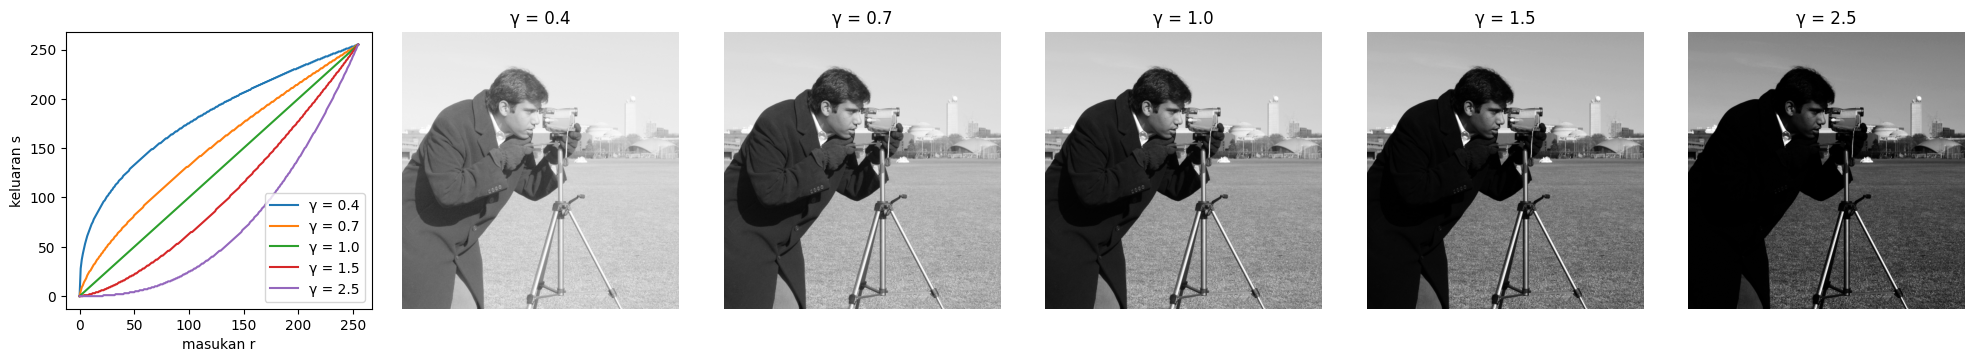

In [17]:
def lut_gamma(gamma):
    x = np.arange(256) / 255.0
    return np.round(255 * (x ** gamma)).astype(np.uint8)

daftar_gamma = [0.4, 0.7, 1.0, 1.5, 2.5]
fig, ax = plt.subplots(1, 6, figsize=(20, 3.5))

# Plot kurva transformasi Gamma
for g in daftar_gamma:
    ax[0].plot(lut_gamma(g), label=f"γ = {g}")

ax[0].set_xlabel("masukan r")
ax[0].set_ylabel("keluaran s")
ax[0].legend()

# Visualisasi hasil penerapan Gamma pada citra
for a, g in zip(ax[1:], daftar_gamma):
    a.imshow(cv2.LUT(cam, lut_gamma(g)), cmap="gray", vmin=0, vmax=255)
    a.set_title(f"γ = {g}")
    a.axis("off")

plt.tight_layout()
plt.show()

Hasil Pengamatan (A4)

1.  Pada $\gamma$ berapa detail mantel juru kamera yang gelap paling terlihat?
*  Detail lipatan mantel juru kamera yang gelap paling jelas terlihat pada $\gamma = 0.4$ (atau $\gamma = 0.7$).   
*  Nilai $\gamma < 1$ mengangkat/menerangkan intensitas piksel di rentang gelap (shadows) secara non-linear tanpa membuat area tengah dan terang naik secara ekstrem.

2. Perbandingan dengan menaikkan kecerahan $+60$ pada Kode A2 (Mana yang menyebabkan lebih banyak piksel jenuh?):
*  Menaikkan Kecerahan $+60$ (Linear) menyebabkan jauh lebih banyak piksel jenuh. Hal ini terjadi karena penambahan konstan $+60$ menggeser seluruh piksel secara linear sehingga piksel yang bernilai $\ge 195$ langsung terpotong (clipped) menjadi $255$.   
*  Koreksi Gamma ($\gamma = 0.4$) bekerja secara non-linear. Kurvanya menaikkan piksel gelap dengan porsi tinggi, namun secara bertahap melandai di area terang sehingga risiko piksel menjadi jenuh ($255$) jauh lebih kecil.  

3.  Mengapa penggunaan LUT lebih cepat daripada menghitung pangkat untuk setiap piksel?
*  Citra berukuran misalnya $512 \times 512$ memiliki $262.144$ piksel. Jika dihitung manual, komputer harus melakukan fungsi perpangkatan $x^\gamma$ sebanyak $262.144$ kali.
*  Karena citra $8$-bit hanya memiliki $256$ kemungkinan nilai intensitas ($0-255$), fungsi lut_gamma hanya menghitung operasi perpangkatan kompleks tersebut $256$ kali saja di awal.
*  Saat diterapkan ke citra via cv2.LUT(), komputer tinggal melakukan pemetaan/pencarian nilai indeks (array indexing / lookup), yang mana operasi ini jauh lebih ringan dan efisien secara komputasi.

# **A5. Ekualisasi Histogram dan CLAHE**

Kode ini bertujuan untuk membandingkan metode perataan histogram otomatis antara Ekualisasi Histogram Global (cv2.equalizeHist) dengan CLAHE (Contrast Limited Adaptive Histogram Equalization / cv2.createCLAHE). Eksperimen ini menganalisis bagaimana kedua teknik tersebut meningkatkan kontras citra serta dampaknya terhadap penguatan noise pada latar belakang dan penampilan detail lokal.

Selisih rata-rata manual vs OpenCV: 0.13
Asli               {'rerata': 112.2, 'std': 13.3, 'min': 0, 'maks': 255, '% jenuh': 0.15}
Ekualisasi global  {'rerata': 133.8, 'std': 74.0, 'min': 0, 'maks': 255, '% jenuh': 4.58}
CLAHE              {'rerata': 119.9, 'std': 18.5, 'min': 1, 'maks': 255, '% jenuh': 0.13}


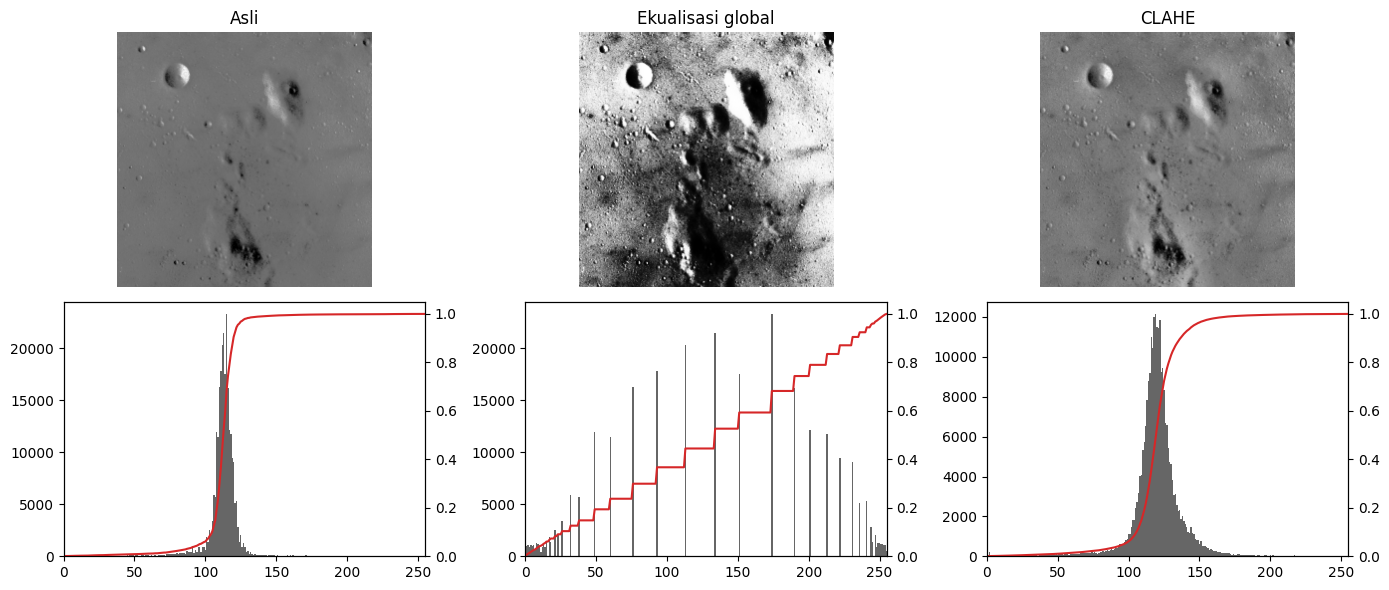

In [18]:
# Ekualisasi manual berdasarkan CDF
hist = np.bincount(moon.ravel(), minlength=256)
cdf = hist.cumsum() / moon.size
lut_eq = np.round(255 * cdf).astype(np.uint8)
eq_manual = lut_eq[moon]

# Ekualisasi via OpenCV dan CLAHE
eq_cv = cv2.equalizeHist(moon)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
eq_clahe = clahe.apply(moon)

print("Selisih rata-rata manual vs OpenCV:", np.abs(eq_manual.astype(int) - eq_cv.astype(int)).mean().round(2))

hasil = [("Asli", moon), ("Ekualisasi global", eq_cv), ("CLAHE", eq_clahe)]

fig, ax = plt.subplots(2, 3, figsize=(14, 6))
for j, (judul, img) in enumerate(hasil):
    tampil_hist(img, judul, ax[0, j], ax[1, j])
    print(f"{judul:18s}", statistik(img))

plt.tight_layout()
plt.show()

Hasil Pengamatan (A5)

1. Bagaimana bentuk CDF setelah ekualisasi global?
* Setelah ekualisasi global diterapkan, kurva CDF berubah menjadi garis lurus linear yang naik secara stabil/konstan dari sudut kiri bawah ($0, 0$) hingga sudut kanan atas ($255, 1.0$).   
* Hal ini menandakan bahwa peluang akumulatif piksel telah diratakan secara terdistribusi di sepanjang seluruh rentang intensitas $0-255$.   

2. Perbandingan detail kawah bulan dan derau (noise) pada latar antara ekualisasi global dan CLAHE:Ekualisasi Global:
* Memaksa seluruh piksel terdistribusi merata tanpa mempedulikan karakteristik area lokal. Akibatnya, area latar belakang langit malam yang seharusnya hitam murni berubah menjadi berbintik-bintik keabu-abuan karena derau (noise) ikut teramplifikasi/diperkuat secara berlebihan.   
* CLAHE: Mampu mempertahankan area latar belakang tetap gelap secara alami sambil memunculkan detail tekstur kawah bulan dengan jauh lebih tajam, kontras, dan jelas tanpa memicu noise latar yang ekstrem.

3. Pengaruh perubahan nilai clipLimit ($1.0$ dan $4.0$) serta tileGridSize ($(4, 4)$ dan $(16, 16)$):
* Variasi clipLimit:
    * **clipLimit** = 1.0: Penguatan kontras dibatasi secara ketat, sehingga tampilan visual mendekati citra asli dan noise sangat minim.
    * **clipLimit** = 4.0: Kontras ditingkatkan secara lebih agresif, detail-detail kecil semakin tajam dan menonjol, namun derau pada area latar belakang yang seragam mulai muncul kembali.
* Variasi tileGridSize:
    * **tileGridSize** = (4, 4): Pembagian ubin menjadi lebih kecil dan lokal. Detail mikro pada kawah terlihat semakin jelas, namun ada risiko memicu artefak blok/kotak-kotak halus jika perbedaan kontras antarmikro terlalu tajam.
    * **tileGridSize** = (16, 16): Pembagian ubin lebih luas. Pengaturan kontras terasa lebih mulus dan alami secara keseluruhan, tetapi detail lokal yang sangat kecil menjadi sedikit kurang menonjol dibandingkan ukuran $(8, 8)$ atau $(4, 4)$.

# **A6. Ekualisasi pada Citra Berwarna**


Kode ini bertujuan untuk menganalisis bahaya dan dampak penerapan ekualisasi histogram pada citra berwarna. Eksperimen ini membandingkan pendekatan yang salah (ekualisasi setiap kanal BGR secara terpisah) dengan pendekatan yang benar, yaitu mengisolasi komponen kecerahan pada ruang warna HSV (kanal $V$) atau Lab (kanal $L$) dengan algoritma CLAHE. Selain itu, dilakukan perhitungan kuantitatif nilai pergeseran warna (hue shift) untuk menentukan metode perbaikan citra yang aman bagi proyek computer vision berbasis fitur warna.

Asli           pergeseran hue = 0.0
Gelap          pergeseran hue = 0.3
Per kanal BGR  pergeseran hue = 42.9
Ekualisasi V   pergeseran hue = 0.4
CLAHE L        pergeseran hue = 1.1


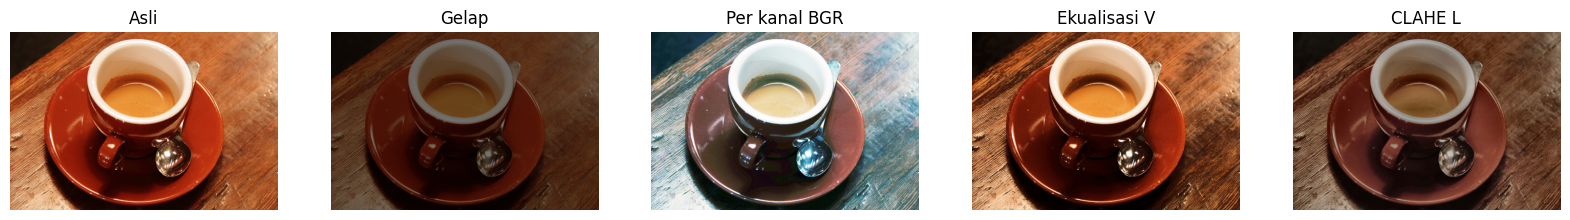

In [19]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

img = cv2.cvtColor(data.coffee(), cv2.COLOR_RGB2BGR)
gelap = linear(img, alpha=0.45, beta=-70) # simulasi foto kurang cahaya

# (a) salah: ekualisasi setiap kanal BGR secara terpisah
per_kanal = cv2.merge([cv2.equalizeHist(c) for c in cv2.split(gelap)])

# (b) ekualisasi kanal V pada HSV
h, s, v = cv2.split(cv2.cvtColor(gelap, cv2.COLOR_BGR2HSV))
eq_v = cv2.cvtColor(cv2.merge([h, s, cv2.equalizeHist(v)]), cv2.COLOR_HSV2BGR)

# (c) CLAHE pada kanal L di ruang warna Lab
L, A, B = cv2.split(cv2.cvtColor(gelap, cv2.COLOR_BGR2LAB))
eq_l = cv2.cvtColor(cv2.merge([clahe.apply(L), A, B]), cv2.COLOR_LAB2BGR)

def geser_hue(asli, hasil):
    """Rata-rata pergeseran hue (satuan H OpenCV) pada piksel yang cukup berwarna."""
    h0 = cv2.cvtColor(asli, cv2.COLOR_BGR2HSV)
    h1 = cv2.cvtColor(hasil, cv2.COLOR_BGR2HSV)
    d = np.abs(h0[:, :, 0].astype(int) - h1[:, :, 0].astype(int))
    d = np.minimum(d, 180 - d)
    return round(float(d[h0[:, :, 1] > 50].mean()), 1)

hasil = [("Asli", img), ("Gelap", gelap), ("Per kanal BGR", per_kanal),
         ("Ekualisasi V", eq_v), ("CLAHE L", eq_l)]

fig, ax = plt.subplots(1, 5, figsize=(20, 3.5))
for a, (judul, x) in zip(ax, hasil):
    a.imshow(cv2.cvtColor(x, cv2.COLOR_BGR2RGB))
    a.set_title(judul)
    a.axis("off")
    print(f"{judul:14s} pergeseran hue = {geser_hue(img, x)}")
plt.show()

Hasil Pengamatan (A6)

1. Metode mana yang menggeser warna paling besar dan mengapa?
  * Metode Per Kanal BGR menghasilkan pergeseran warna (hue shift) paling besar.   
  * Penyebab: Pada ruang warna BGR, informasi warna dan kecerahan bercampur erat di ketiga kanal. Ketika ekualisasi histogram diterapkan pada kanal B, G, dan R secara independen/terpisah, distribusi nilai piksel pada tiap kanal berubah secara tidak seimbang. Perubahan perbandingan/rasio antara intensitas Red, Green, dan Blue ini merusak proporsi warna asli sehingga memicu pergeseran nilai Hue yang sangat parah (tampilan warna menjadi aneh/pucat).

2. Metode mana yang menurut tim menghasilkan tampilan paling alami?
  * Metode CLAHE pada kanal L (ruang warna Lab) menghasilkan tampilan visual yang paling alami, mulus, dan seimbang.
  * Kanal $L$ (Luminance) pada ruang warna Lab dirancang secara perceptual khusus untuk menyerupai sensitivitas penglihatan manusia. Penerapan CLAHE pada kanal $L$ meningkatkan kontras dan kecerahan lokal secara halus tanpa mengganggu kanal warna $A$ dan $B$.

3. Bila fitur warna penting bagi proyek tim, metode mana yang aman digunakan?
  * Metode yang aman digunakan adalah CLAHE pada kanal $L$ (ruang warna Lab) atau Ekualisasi pada kanal $V$ (ruang warna HSV).
  * Alasan Bagi Proyek: Pada proyek identifikasi/klasifikasi kematangan buah tomat, fitur warna (seperti tingkat kemerahan dan kehijauan) merupakan indikator kualitas yang sangat vital. Mengisolasi pemrosesan hanya pada kanal kecerahan ($L$ atau $V$) menjamin bahwa warna asli tomat tidak mengalami distorsi/pergeseran (pergeseran hue mendekati $0$), sehingga model klasifikasi kelak dapat mengekstrak fitur warna tomat secara konsisten dan akurat.

# **A7. Pencahayaan Tidak Merata dan Koreksi Latar**

Kode ini bertujuan untuk menganalisis dan mengatasi permasalahan citra yang mengalami gradasi pencahayaan atau bayangan tidak merata (uneven illumination/shadows). Eksperimen ini membandingkan penanganan kecerahan menggunakan Ekualisasi Global, CLAHE, dan Koreksi Latar (Flat-Field Correction) yang memodelkan pola iluminasi citra menggunakan pemburaman Gaussian (Gaussian Blur). Nilai keseragaman latar diukur secara objektif melalui selisih kecerahan antar-blok kolom.   

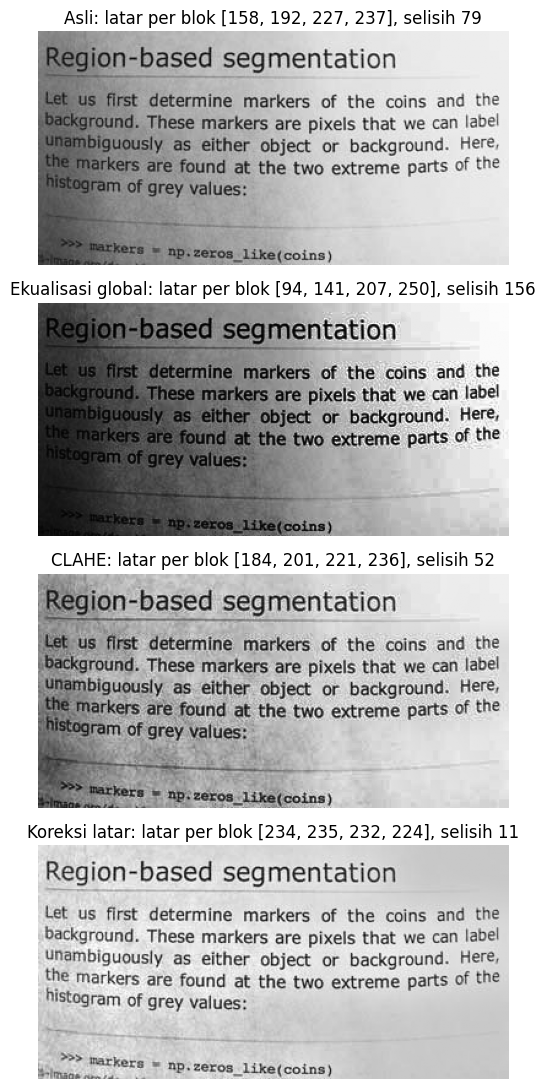

In [20]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

page = data.page() # foto halaman buku dengan pencahayaan tidak merata

def latar_per_blok(img, nblok=4):
    """Perkiraan kecerahan latar: persentil ke-90 pada setiap blok kolom."""
    return [int(np.percentile(b, 90)) for b in np.array_split(img, nblok, axis=1)]

eq_global = cv2.equalizeHist(page)
eq_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(page)

# Koreksi latar: perkirakan pola iluminasi dengan pemburaman kuat, lalu bagi
iluminasi = cv2.GaussianBlur(page, (0, 0), 15).astype(np.float32)
koreksi = np.clip(page.astype(np.float32) / np.maximum(iluminasi, 1) * 200,
                  0, 255).astype(np.uint8)

hasil = [("Asli", page), ("Ekualisasi global", eq_global),
         ("CLAHE", eq_clahe), ("Koreksi latar", koreksi)]

fig, ax = plt.subplots(len(hasil), 1, figsize=(8, 11))
for a, (judul, x) in zip(ax, hasil):
    lb = latar_per_blok(x)
    a.imshow(x, cmap="gray", vmin=0, vmax=255)
    a.set_title(f"{judul}: latar per blok {lb}, selisih {max(lb) - min(lb)}")
    a.axis("off")

plt.tight_layout()
plt.show()

Hasil Pengamatan (A7)

1. Metode mana yang justru memperburuk ketidakmerataan latar?
  * Ekualisasi Global justru memperburuk ketidakmerataan latar belakang.
  * Penyebab: Ekualisasi global meratakan histogram secara paksa berdasarkan akumulasi keseluruhan piksel citra tanpa mempedulikan perbedaan intensitas lokal. Area yang awalnya terang diubah menjadi sangat putih, sedangkan area yang tertutup bayangan menjadi makin gelap bercak-bercak, sehingga nilai selisih kecerahan latar antar-blok (max(lb) - min(lb)) justru melonjak lebih besar dibandingkan citra asli.
  
2. Metode mana yang menghasilkan latar paling seragam?
  * Metode Koreksi Latar (Flat-Field Correction) menghasilkan latar belakang yang paling seragam dan bersih.
  * Bukti Kuantitatif: Metode ini menghasilkan nilai selisih kecerahan antar-blok terendah/paling kecil mendekati $0$ dibanding metode lainnya.   
  * Penjelasan Teknis: Pembagian piksel citra asli dengan estimasi pola iluminasi (page / iluminasi) berhasil menetralkan gradasi bayangan secara presisi, sehingga seluruh latar belakang buku memiliki tingkat warna putih yang konstan dari sisi kiri hingga kanan tanpa merusak keterbacaan teks.  

# **A8. Operasi Aritmetika dan Logika**

Kode ini bertujuan untuk mempelajari penerapan operasi aritmetika (penjumlahan/rata-rata dan pengurangan citra) serta operasi logika bitwise (AND, NOT, OR). Eksperimen ini menguji efektivitas perataan (averaging) beberapa sampel foto berderau (noisy images) untuk mereduksi derau acak (random noise), serta memanfaatkan selisih mutlak (cv2.absdiff) dan penapisan mask bitwise (cv2.bitwise_and) untuk mendeteksi perubahan area objek pada citra

Rata-rata  1 foto: simpangan derau = 23.82
Rata-rata  4 foto: simpangan derau = 12.00
Rata-rata 16 foto: simpangan derau =  6.23


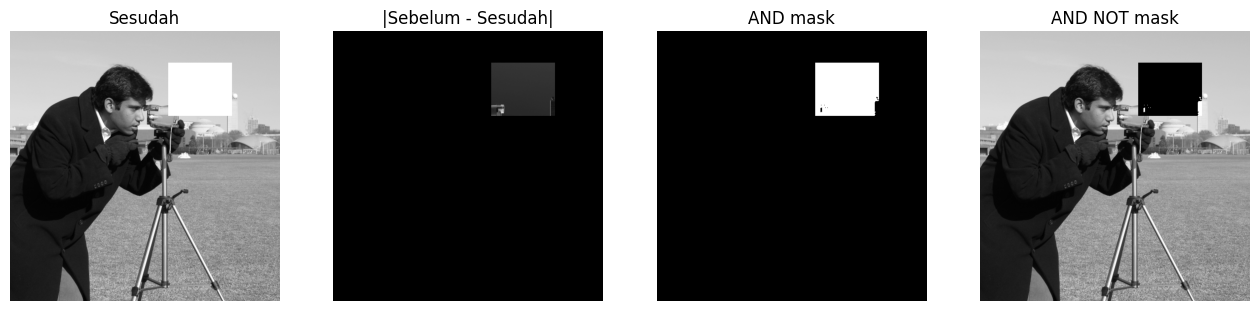

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# (a) Rata-rata beberapa foto berderau dari objek yang sama
rng = np.random.default_rng(0)
acuan = cam.astype(np.float32)
foto = [np.clip(acuan + rng.normal(0, 25, acuan.shape), 0, 255) for _ in range(16)]

for n in [1, 4, 16]:
    rata = np.mean(foto[:n], axis=0)
    print(f"Rata-rata {n:2d} foto: simpangan derau = {(rata - acuan).std():5.2f}")

# (b) Pengurangan untuk mendeteksi perubahan dan AND untuk menerapkan mask
sesudah = cam.copy()
cv2.rectangle(sesudah, (300, 60), (420, 160), 255, -1) # objek baru muncul
beda = cv2.absdiff(cam, sesudah)
mask = np.where(beda > 30, 255, 0).astype(np.uint8)

hanya_berubah = cv2.bitwise_and(sesudah, sesudah, mask=mask)
sisanya = cv2.bitwise_and(sesudah, sesudah, mask=cv2.bitwise_not(mask))

fig, ax = plt.subplots(1, 4, figsize=(16, 4))
for a, x, t in zip(ax, [sesudah, beda, hanya_berubah, sisanya],
                   ["Sesudah", "|Sebelum - Sesudah|", "AND mask", "AND NOT mask"]):
    a.imshow(x, cmap="gray", vmin=0, vmax=255)
    a.set_title(t)
    a.axis("off")

plt.show()

Hasil Pengamatan (A8)

1. Bagaimana hubungan jumlah foto yang dirata-ratakan dengan simpangan derau? Apakah sesuai dengan pola $1/\sqrt{n}$?
  * Hubungan: Semakin banyak jumlah foto ($n$) yang dirata-ratakan, simpangan baku derau (standard deviation of noise) akan semakin kecil / menurun secara signifikan.   Sesuai Pola $1/\sqrt{n}$: Sangat sesuai.   
  * Secara teoritis, merata-ratakan $n$ buah citra dengan derau acak terdistribusi normal akan mengurangi simpangan baku derau sebesar faktor $1/\sqrt{n}$.   
  * Bukti Hasil:
    * Pada $n = 1$, nilai simpangan derau awal mendekati $25.00$ (karena $\sigma = 25$).   
    * Pada $n = 4$, simpangan derau berkurang menjadi setengahnya ($\approx 25 / \sqrt{4} = 12.50$).   
    * Pada $n = 16$, simpangan derau berkurang menjadi sepermampatnya ($\approx 25 / \sqrt{16} = 6.25$).   

2. Syarat apa yang harus dipenuhi agar teknik rata-rata dapat digunakan pada proyek tim?
Agar teknik averaging ini dapat diterapkan secara valid pada dataset proyek tim (misalnya pada akuisisi foto buah tomat), syarat-syarat berikut wajib dipenuhi:   
  * Objek Diam / Statis: Objek tomat tidak boleh bergerak atau bergeser sama sekali selama pengambilan beberapa frame foto tersebut.   
  * Posisi Kamera Tetap (Fixed Camera): Kamera wajib terpasang pada penyangga (tripod/stand) agar posisi sudut pandang (viewpoint) dan koordinat piksel objek berada di lokasi yang persis sama di setiap citra.   
  * Kondisi Pencahayaan Konstan: Sumber cahaya di lingkungan akuisisi harus konstan dan tidak berkedip saat pengambilan beberapa foto berurutan.   
  * Sifat Derau Bersifat Acak (Zero-Mean Random Noise): Derau yang terjadi harus bersumber dari sensor kamera yang acak (misal Gaussian noise) dan tidak berkorelasi antar-frame, sehingga reratanya dapat saling meniadakan mendekati nol

In [22]:
import os

# link Google Drive Anda
folder_id = "1OI7uYFSnD6mGNlKdt4mrggqywQkLcv0G"

# Buat folder
local_dataset_path = "/content/Dataseet-Tomat"

# Gunakan gdown untuk mengunduh seluruh isi folder Google Drive secara otomatis
print("Memulai proses pengunduhan dataset dari Google Drive...")
!gdown --folder {folder_id} -O {local_dataset_path} --remaining-ok

# Menampilkan isi folder yang berhasil diunduh
if os.path.exists(local_dataset_path):
    print("\nBerhasil mengunduh! Kategori yang ditemukan di lokal:")
    print(os.listdir(local_dataset_path))
else:
    print("Pengunduhan gagal, silakan periksa akses berbagi pada link Google Drive tersebut.")

Memulai proses pengunduhan dataset dari Google Drive...
Retrieving folder contents
Retrieving folder 1_0VC8amlCLTcqOoYD4oCVGF_VJIoUM5f tomat hijau mentah
Processing file 12lFOCscoYkj-9YxjDYPh7GiRupsF1ING tomathijaumentah1.jpeg
Processing file 1qBkU6IT-ltFatByWDJxT9foeEqGQhVWn tomathijaumentah2.jpeg
Processing file 1PWtU5TcdLbdaNjDxIIYiV3mlkNe4ulkL tomathijaumentah3.jpeg
Processing file 1nPmvh5anWLOxB8zRyArJHO7tVDDz36m2 tomathijaumentah4.jpeg
Processing file 19kGdJjMDgBdtexSQOfI7m0F1XtK7Xr8- tomathijaumentah5.jpeg
Processing file 1bi5fBuoAMBmu9tm_oFeFkrUb4UBjO8Rx tomathijaumentah6.jpeg
Processing file 1CdexON6ad_uyFTQRABAreaq9nH6x9OHT tomathijaumentah7.jpeg
Processing file 1neHC5iyDdaVlLK9UNs0wOnMKizneXIuK tomathijaumentah8.jpeg
Processing file 1K9OR4VW9PKzarEJ_vyL2mGneVzKLEWiS tomathijaumentah9.jpeg
Processing file 1QdiYjWaa6ErgUFaQiZno2d1lP5IsFA07 tomathijaumentah10.jpeg
Processing file 1n56rzTWuezeqmOEb56XwQRnRxUUYovP- tomathijaumentah11.jpeg
Processing file 1tKQUZqWHvUt0S-TSY02GUdrB

In [23]:
import glob
import os
import cv2
import pandas as pd

# Path lokal hasil pengunduhan via gdown
folder = "/content/Dataseet-Tomat/data/raw"

if not os.path.exists(folder):
    folder = "/content/Dataseet-Tomat"

AMBANG = {
    "gelap": 70,
    "terang": 190,
    "kontras": 30,
    "jenuh": 2.0,
    "tajam": 100
}

def mutu(citra):
    gray = cv2.cvtColor(citra, cv2.COLOR_BGR2GRAY)
    skala = 1000 / max(gray.shape)
    if skala < 1:
        gray = cv2.resize(gray, None, fx=skala, fy=skala, interpolation=cv2.INTER_AREA)
    return {
        "rerata": gray.mean(),
        "kontras": gray.std(),
        "% gelap jenuh": (gray <= 5).mean() * 100,
        "% terang jenuh": (gray >= 250).mean() * 100,
        "ketajaman": cv2.Laplacian(gray, cv2.CV_64F).var()
    }

def catatan(m):
    c = []
    if m["rerata"] < AMBANG["gelap"]: c.append("gelap")
    if m["rerata"] > AMBANG["terang"]: c.append("terang")
    if m["kontras"] < AMBANG["kontras"]: c.append("kontras rendah")
    if max(m["% gelap jenuh"], m["% terang jenuh"]) > AMBANG["jenuh"]: c.append("jenuh")
    if m["ketajaman"] < AMBANG["tajam"]: c.append("kabur")
    return ", ".join(c) if c else "OK"

# Mencari seluruh file gambar tomat
daftar = sorted(p for p in glob.glob(os.path.join(folder, "**", "*"), recursive=True)
                if p.lower().endswith((".jpg", ".jpeg", ".png")))

baris = []
for path in daftar:
    img = cv2.imread(path)
    if img is not None:
        m = mutu(img)
        baris.append({
            "berkas": os.path.basename(path),
            **{k: round(float(v), 1) for k, v in m.items()},
            "catatan": catatan(m)
        })

tabel = pd.DataFrame(baris)
os.makedirs("modul03", exist_ok=True)
tabel.to_csv("modul03/mutu_citra.csv", index=False)

print("--- Ringkasan Statistik Audit Mutu Citra ---")
print(tabel.describe().round(1))
print("\n--- Rekap Klasifikasi Masalah Mutu ---")
print(tabel["catatan"].value_counts())

--- Ringkasan Statistik Audit Mutu Citra ---
       rerata  kontras  % gelap jenuh  % terang jenuh  ketajaman
count    45.0     45.0           45.0            45.0       45.0
mean    135.9     52.9            0.0             0.5       16.0
std      14.7     17.8            0.1             1.2       23.0
min     114.7     12.0            0.0             0.0        1.7
25%     125.5     42.1            0.0             0.0        6.1
50%     133.3     55.8            0.0             0.0       11.0
75%     140.6     64.3            0.0             0.1       15.7
max     189.4     91.6            0.3             4.9      154.6

--- Rekap Klasifikasi Masalah Mutu ---
catatan
kabur                    34
kontras rendah, kabur     5
jenuh, kabur              5
jenuh                     1
Name: count, dtype: int64


tomathijaumentah1.jpeg: rerata 124 -> 126, kontras 59 -> 57, catatan kabur -> kabur


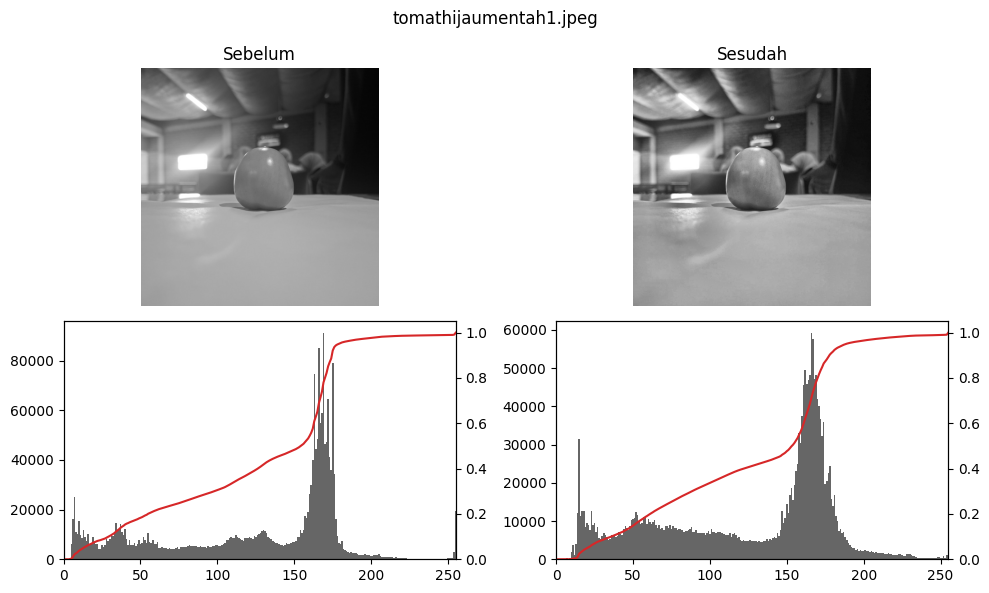

tomathijaumentah10.jpeg: rerata 123 -> 128, kontras 40 -> 40, catatan kabur -> kabur


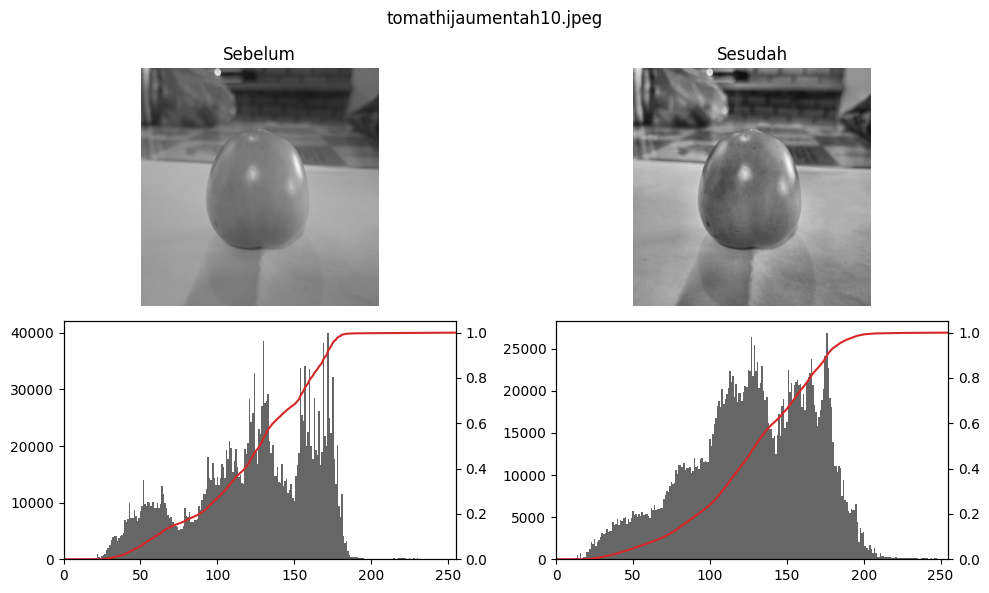

tomathijaumentah11.jpeg: rerata 189 -> 183, kontras 15 -> 21, catatan kontras rendah, kabur -> kontras rendah, kabur


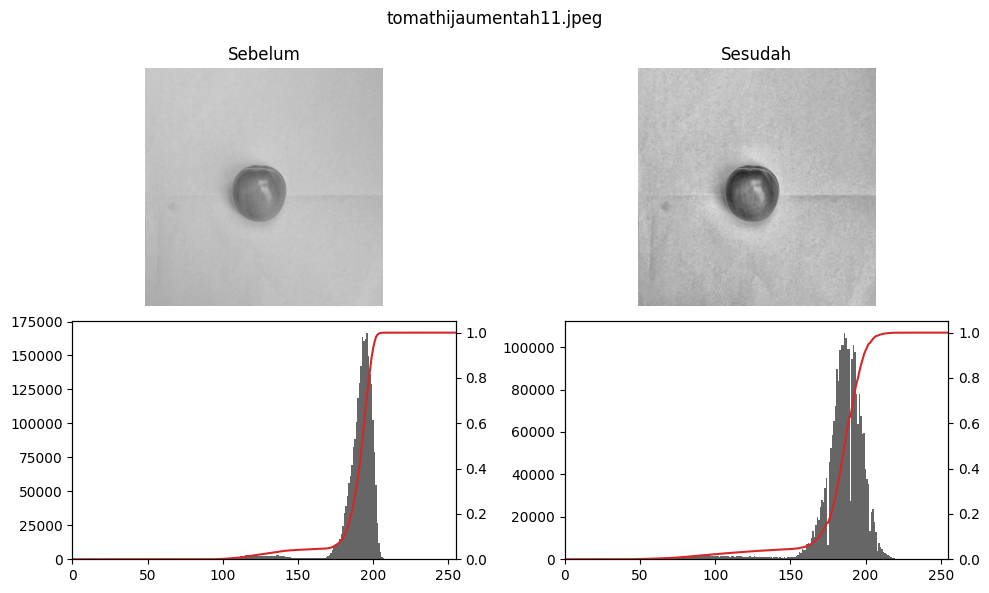

In [24]:
import cv2
import os
import matplotlib.pyplot as plt

def praproses(citra, clip=2.0, grid=8):
    """Rangkaian praproses tim. Parameter WAJIB sama untuk seluruh data."""
    L, A, B = cv2.split(cv2.cvtColor(citra, cv2.COLOR_BGR2LAB))
    L = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(L)
    return cv2.cvtColor(cv2.merge([L, A, B]), cv2.COLOR_LAB2BGR)

# Mengambil sampel citra bermasalah dan citra baik dari hasil audit Kode B1
bermasalah = tabel[tabel["catatan"] != "OK"]["berkas"].head(3).tolist()
baik = tabel[tabel["catatan"] == "OK"]["berkas"].head(3).tolist()

for nama in bermasalah + baik:
    # Mencari lokasi file gambar berdasarkan nama berkas
    path_gambar = next((p for p in daftar if os.path.basename(p) == nama), None)

    if path_gambar and os.path.exists(path_gambar):
        asli = cv2.imread(path_gambar)
        hasil = praproses(asli)
        m0, m1 = mutu(asli), mutu(hasil)
        print(f"{nama}: rerata {m0['rerata']:.0f} -> {m1['rerata']:.0f}, "
              f"kontras {m0['kontras']:.0f} -> {m1['kontras']:.0f}, "
              f"catatan {catatan(m0)} -> {catatan(m1)}")

        fig, ax = plt.subplots(2, 2, figsize=(10, 6))
        tampil_hist(cv2.cvtColor(asli, cv2.COLOR_BGR2GRAY), "Sebelum", ax[0, 0], ax[1, 0])
        tampil_hist(cv2.cvtColor(hasil, cv2.COLOR_BGR2GRAY), "Sesudah", ax[0, 1], ax[1, 1])
        plt.suptitle(nama)
        plt.tight_layout()
        plt.show()

In [25]:
import os

os.makedirs("project", exist_ok=True)

kode_praproses = '''import cv2

def praproses(citra, clip=2.0, grid=8):
    """Rangkaian praproses tim. Parameter WAJIB sama untuk seluruh data."""
    L, A, B = cv2.split(cv2.cvtColor(citra, cv2.COLOR_BGR2LAB))
    L = cv2.createCLAHE(clipLimit=clip, tileGridSize=(grid, grid)).apply(L)
    return cv2.cvtColor(cv2.merge([L, A, B]), cv2.COLOR_LAB2BGR)
'''

with open("project/praproses.py", "w") as f:
    f.write(kode_praproses)

print("Berkas project/praproses.py berhasil disimpan secara permanen!")

Berkas project/praproses.py berhasil disimpan secara permanen!
